# Schott--Stommel beta spiral

This notebook reproduces the local planetary-geostrophic mechanism and absolute-velocity inversion developed by Schott and Stommel (1978), *Beta spirals and absolute velocities in different oceans* ([doi:10.1016/0011-7471(78)90001-7](https://doi.org/10.1016/0011-7471(78)90001-7)). It is a synthetic, nondimensional water-column experiment rather than a full basin solve: the assumptions in the paper are steady geostrophy, negligible relative vorticity, adiabatic motion, and a linear beta plane.

The example shows three linked ideas:

1. downwelling turns the horizontal velocity clockwise with increasing depth in the Northern Hemisphere;
2. isopycnal slopes encode the turning through thermal wind and potential-vorticity conservation; and
3. observations at many depths determine the unknown reference velocity by an overdetermined least-squares fit.

In [1]:
using Pkg
Pkg.activate(joinpath(@__DIR__, "..", "PlanetaryGeostrophy"))
using PlanetaryGeostrophy
using LinearAlgebra
using Random
using Statistics
using Plots

default(; linewidth=2, framestyle=:box, legend=:best)

  Activating project at `~/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy`


## Local PG column

Let $z$ increase upward, write $(u,v)=V(\cos\theta,\sin\theta)$, and take density to increase downward, so $\rho_z<0$. Schott and Stommel combine steady density conservation, thermal wind, and linear potential-vorticity conservation:

$$u\rho_x+v\rho_y+w\rho_z=0,\qquad u_z=\gamma\rho_y,\qquad v_z=-\gamma\rho_x,\qquad w_z=\frac{\beta}{f}v.$$

For constant speed $V$, no local heating, and uniform $\rho_z$, these reduce to

$$\theta_z=\frac{\rho_z}{\gamma V^2}w,\qquad w_z=\frac{\beta}{f}V\sin\theta.$$

The constant-speed choice closes this pedagogical column without adding dynamics not present in the paper. Starting with $w=0$ at the base and an equatorward component ($v<0$), the beta constraint generates downwelling above. Because $\rho_z<0$, the velocity angle increases upward and therefore turns clockwise when followed downward.

In [2]:
H = 1.0
Nz = 101
z = collect(range(-H, 0.0; length=Nz))
speed = 1.0
gamma = 1.0
rho_z = -1.0
beta_over_f = 2.0
theta_bottom = -0.8
w_bottom = 0.0

rhs(theta, w) = (
    rho_z * w / (gamma * speed^2),
    beta_over_f * speed * sin(theta),
)

function integrate_column(z, theta0, w0)
    theta = similar(z)
    w = similar(z)
    theta[1], w[1] = theta0, w0
    for k in 1:(length(z) - 1)
        dz = z[k + 1] - z[k]
        k1 = rhs(theta[k], w[k])
        k2 = rhs(theta[k] + dz * k1[1] / 2, w[k] + dz * k1[2] / 2)
        k3 = rhs(theta[k] + dz * k2[1] / 2, w[k] + dz * k2[2] / 2)
        k4 = rhs(theta[k] + dz * k3[1], w[k] + dz * k3[2])
        theta[k + 1] = theta[k] + dz * (k1[1] + 2k2[1] + 2k3[1] + k4[1]) / 6
        w[k + 1] = w[k] + dz * (k1[2] + 2k2[2] + 2k3[2] + k4[2]) / 6
    end
    return theta, w
end

theta, w = integrate_column(z, theta_bottom, w_bottom)
u = speed .* cos.(theta)
v = speed .* sin.(theta)

101-element Vector{Float64}:
 -0.7173560908995228
 -0.7173061109540522
 -0.7171561559381835
 -0.7169061803464405
 -0.7165561084462643
 -0.7161058344428126
 -0.7155552227095733
 -0.7149041080846842
 -0.7141522962328208
 -0.7132995640724799
  ⋮
 -0.2532535200379571
 -0.2431493386031095
 -0.23297141297513768
 -0.22272248134682116
 -0.21240534700333816
 -0.2020228762599458
 -0.19157799627772507
 -0.18107369276072988
 -0.17051300753821824

## The spiral

The hodograph connects velocity vectors from the bottom (dark) to the top (light). Reading it from the surface downward, the vector turns clockwise, the Northern Hemisphere subtropical sense identified in the paper. This is a geostrophic beta spiral, not an Ekman spiral: vertical shear follows the horizontal density gradient rather than a local stress balance.

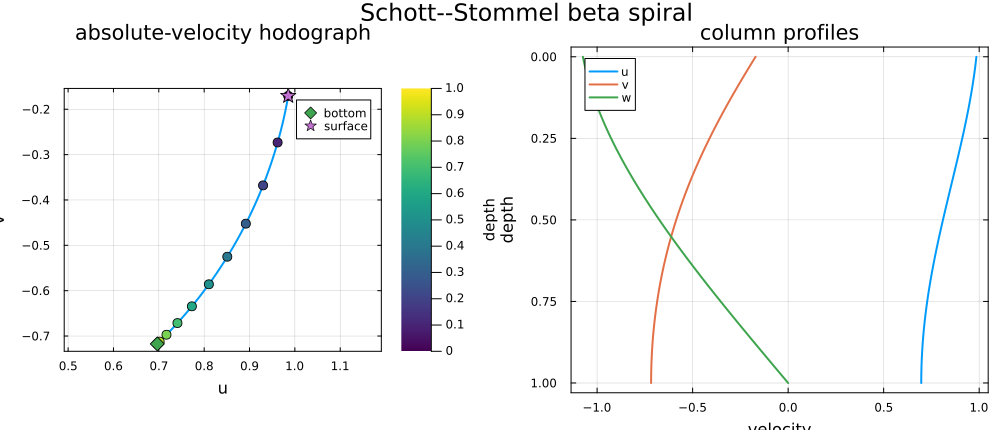

In [3]:
depth = -z
levels = 1:10:Nz
hodograph = plot(
    u, v;
    xlabel="u", ylabel="v", aspect_ratio=:equal,
    title="absolute-velocity hodograph", label=false,
)
scatter!(
    hodograph, u[levels], v[levels];
    marker_z=depth[levels], color=:viridis, colorbar_title="depth",
    markersize=5, label=false,
)
scatter!(hodograph, [u[1]], [v[1]]; marker=:diamond, markersize=7, label="bottom")
scatter!(hodograph, [u[end]], [v[end]]; marker=:star5, markersize=8, label="surface")

profiles = plot(u, depth; xlabel="velocity", ylabel="depth", yflip=true, label="u")
plot!(profiles, v, depth; label="v")
plot!(profiles, w, depth; label="w")
plot!(profiles; title="column profiles")

spiral_figure = plot(
    hodograph, profiles;
    layout=(1, 2), size=(1000, 430),
    plot_title="Schott--Stommel beta spiral",
)
savefig(spiral_figure, joinpath(@__DIR__, "pg_beta_spiral.png"))
display(spiral_figure)

## Isopycnal slopes and the beta constraint

For an isopycnal height $h(x,y)$, thermal wind gives

$$h_x=\frac{v_z}{\gamma\rho_z},\qquad h_y=-\frac{u_z}{\gamma\rho_z}.$$

Differentiating density conservation and substituting $w_z=(\beta/f)v$ yields equation (1.6) of Schott and Stommel:

$$u h_{xz}+v\left(h_{yz}-\frac{\beta}{f}\right)=0.$$

The following cell evaluates the slopes and their vertical derivatives analytically from the integrated column. It also verifies both $w=u h_x+v h_y$ and the beta constraint.

In [4]:
theta_z = rho_z .* w ./ (gamma * speed^2)
theta_zz = rho_z .* beta_over_f .* v ./ (gamma * speed^2)
u_z = -speed .* sin.(theta) .* theta_z
v_z = speed .* cos.(theta) .* theta_z
u_zz = -speed .* (cos.(theta) .* theta_z.^2 .+ sin.(theta) .* theta_zz)
v_zz = speed .* (-sin.(theta) .* theta_z.^2 .+ cos.(theta) .* theta_zz)

h_x = v_z ./ (gamma * rho_z)
h_y = -u_z ./ (gamma * rho_z)
h_xz = v_zz ./ (gamma * rho_z)
h_yz = -u_zz ./ (gamma * rho_z)

w_from_slopes = u .* h_x .+ v .* h_y
beta_residual = u .* h_xz .+ v .* (h_yz .- beta_over_f)
constraint_check = (
    maximum_vertical_velocity_error=maximum(abs, w_from_slopes .- w),
    maximum_beta_constraint_residual=maximum(abs, beta_residual),
)
display(constraint_check)

(maximum_vertical_velocity_error = 2.220446049250313e-16, maximum_beta_constraint_residual = 3.3306690738754696e-16)

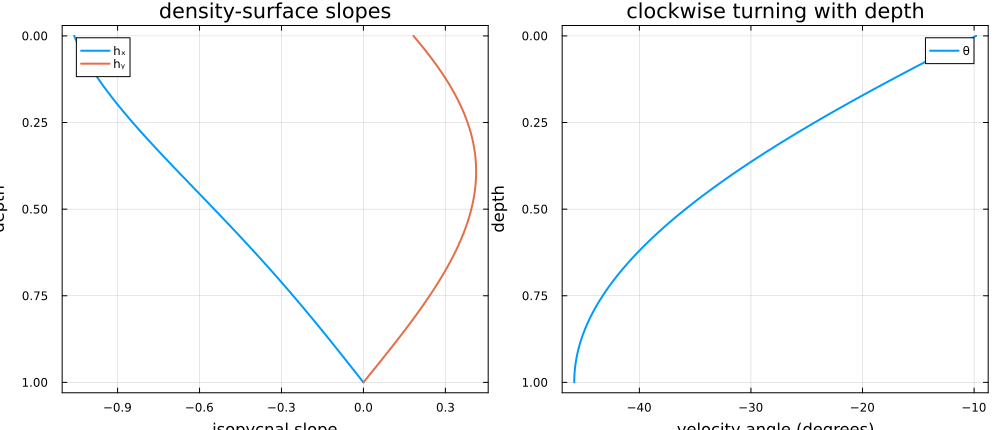

In [5]:
slope_panel = plot(h_x, depth; xlabel="isopycnal slope", ylabel="depth", yflip=true, label="hₓ")
plot!(slope_panel, h_y, depth; label="hᵧ", title="density-surface slopes")

turning_panel = plot(rad2deg.(theta), depth;
    xlabel="velocity angle (degrees)", ylabel="depth", yflip=true,
    label="θ", title="clockwise turning with depth")

slope_figure = plot(slope_panel, turning_panel; layout=(1, 2), size=(1000, 430))
savefig(slope_figure, joinpath(@__DIR__, "pg_beta_spiral_slopes.png"))
display(slope_figure)

## Recovering absolute velocity

Hydrography determines vertical shear, so suppose the measured current is relative to the bottom level: $u=u_0+u'$ and $v=v_0+v'$. At every sampled depth, equation (1.7) gives

$$u_0 h_{xz}+v_0\left(h_{yz}-\frac{\beta}{f}\right)=-u'h_{xz}-v'\left(h_{yz}-\frac{\beta}{f}\right).$$

Stacking the equations produces the modestly overdetermined system $A\boldsymbol{u}_0=\boldsymbol{c}$. The exact synthetic observations recover the reference velocity without imposing a level of no motion.

In [6]:
reference_index = 1
u_relative = u .- u[reference_index]
v_relative = v .- v[reference_index]

function reference_velocity(u_relative, v_relative, h_xz, h_yz, q)
    A = hcat(h_xz, h_yz .- q)
    c = .-(u_relative .* h_xz .+ v_relative .* (h_yz .- q))
    estimate = A \ c
    residual = A * estimate - c
    return (; estimate, residual, A, c)
end

exact_fit = reference_velocity(u_relative, v_relative, h_xz, h_yz, beta_over_f)
u_recovered = u_relative .+ exact_fit.estimate[1]
v_recovered = v_relative .+ exact_fit.estimate[2]

display((
    true_reference=(u[reference_index], v[reference_index]),
    recovered_reference=Tuple(exact_fit.estimate),
    rms_residual=sqrt(mean(abs2, exact_fit.residual)),
))

(true_reference = (0.6967067093471654, -0.7173560908995228), recovered_reference = (0.6967067093471647, -0.7173560908995232), rms_residual = 1.5424973443730015e-15)

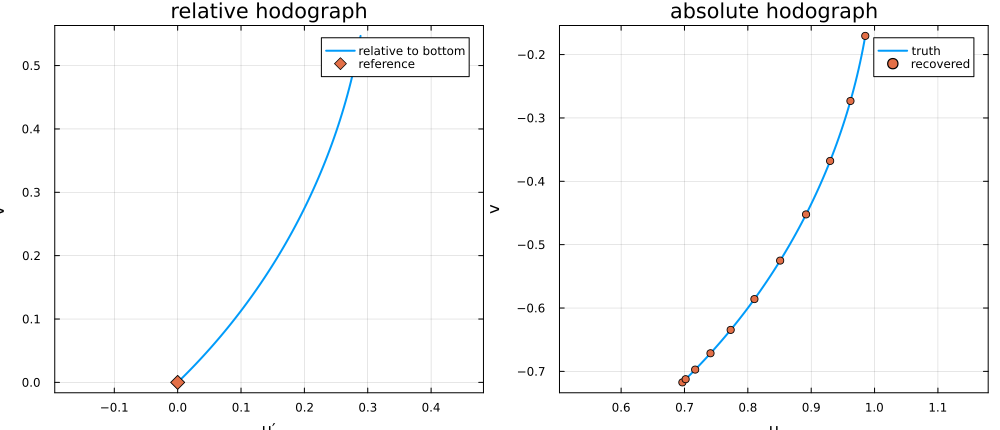

In [7]:
relative_panel = plot(
    u_relative, v_relative;
    xlabel="u′", ylabel="v′", aspect_ratio=:equal,
    title="relative hodograph", label="relative to bottom",
)
scatter!(relative_panel, [0.0], [0.0]; marker=:diamond, markersize=7, label="reference")

absolute_panel = plot(
    u, v;
    xlabel="u", ylabel="v", aspect_ratio=:equal,
    title="absolute hodograph", label="truth",
)
scatter!(absolute_panel, u_recovered[levels], v_recovered[levels];
    marker=:circle, markersize=4, label="recovered")

inversion_figure = plot(relative_panel, absolute_panel; layout=(1, 2), size=(1000, 430))
savefig(inversion_figure, joinpath(@__DIR__, "pg_beta_spiral_inversion.png"))
display(inversion_figure)

## Noisy observations and the wrong-latitude test

Schott and Stommel judged whether beta genuinely constrained the fit by repeating the inversion with deliberately wrong values of $\beta/f$. A credible data set should have a residual minimum near the true latitude. Here small, reproducible perturbations mimic uncertainty in relative velocity and slope derivatives. The recovered offset remains close to the truth, and the residual ratio $R/C$ selects the correct beta parameter.

In [8]:
rng = MersenneTwister(1978)
noise_fraction = 0.015
perturb(values) = values .+ noise_fraction * max(std(values), eps()) .* randn(rng, length(values))

u_relative_observed = perturb(u_relative)
v_relative_observed = perturb(v_relative)
h_xz_observed = perturb(h_xz)
h_yz_observed = perturb(h_yz)

noisy_fit = reference_velocity(
    u_relative_observed, v_relative_observed,
    h_xz_observed, h_yz_observed, beta_over_f,
)

q_trials = range(0.25beta_over_f, 1.75beta_over_f; length=121)
quality = map(q_trials) do q
    fit = reference_velocity(
        u_relative_observed, v_relative_observed,
        h_xz_observed, h_yz_observed, q,
    )
    sum(abs2, fit.residual) / sum(abs2, fit.c)
end
best_q = q_trials[argmin(quality)]

display((
    true_reference=(u[reference_index], v[reference_index]),
    noisy_recovery=Tuple(noisy_fit.estimate),
    true_beta_over_f=beta_over_f,
    residual_minimum=best_q,
))

(true_reference = (0.6967067093471654, -0.7173560908995228), noisy_recovery = (0.6972280517476921, -0.7178457204948453), true_beta_over_f = 2.0, residual_minimum = 2.0)

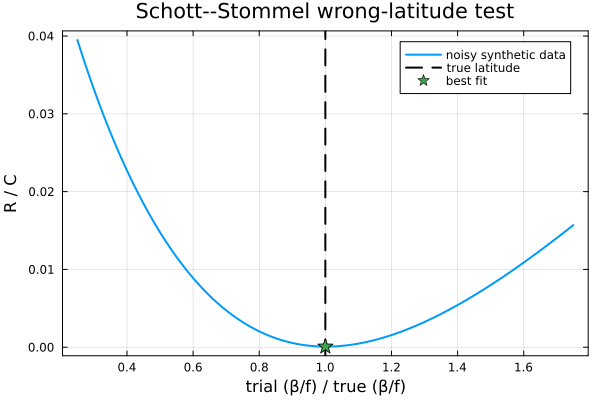

In [9]:
wrong_latitude_figure = plot(
    q_trials ./ beta_over_f, quality;
    xlabel="trial (β/f) / true (β/f)", ylabel="R / C",
    title="Schott--Stommel wrong-latitude test", label="noisy synthetic data",
)
vline!(wrong_latitude_figure, [1.0]; linestyle=:dash, color=:black, label="true latitude")
scatter!(wrong_latitude_figure, [best_q / beta_over_f], [minimum(quality)];
    marker=:star5, markersize=8, label="best fit")
savefig(wrong_latitude_figure, joinpath(@__DIR__, "pg_beta_spiral_wrong_latitude.png"))
display(wrong_latitude_figure)

## Comparison with the frictional PG model

The repository's full PG solver adds vertical viscosity and buoyancy diffusion, a rigid basin boundary, surface wind stress, bottom stress, and a solved surface-pressure field. To compare with the local theory, construct a flat-bottom beta-plane basin with a small Ekman number, $\mathrm{Ek}=0.004$. Two differently oriented buoyancy forcings give the density gradient vertical structure, while a weak subtropical wind stress drives the basin circulation.

This is not fitted to the idealized column above. The useful comparison is qualitative: both solutions produce a curved velocity hodograph, while the full PG column also contains viscous boundary layers and a depth-dependent speed.

In [10]:
pg_Lx, pg_Ly, pg_H = 2.0, 1.2, 1.0
pg_f0, pg_beta = 1.0, 0.35
pg_Ek, pg_Gamma = 0.004, 0.20
pg_tau0 = 4e-4

pg_eta(y) = (y + pg_Ly / 2) / pg_Ly
pg_tau_x(x, y) = -pg_tau0 * cos(pi * pg_eta(y))
pg_wind_curl(x, y) = -pg_tau0 * pi / pg_Ly * sin(pi * pg_eta(y))
pg_restoring_buoyancy(x, y, z) = 0.02z * (1 + 0.25x - 0.15y)
pg_surface_buoyancy(x, y) = 0.006 * (-0.3x + 0.7y)

pg_problem = PGProblem(
    parameters=PGParameters(pg_Ek, pg_Gamma; viscosity=1.0, diffusivity=1.0),
    depth=(x, y) -> pg_H,
    depth_x=(x, y) -> 0.0,
    depth_y=(x, y) -> 0.0,
    coriolis=(x, y) -> pg_f0 + pg_beta * y,
    coriolis_x=(x, y) -> 0.0,
    coriolis_y=(x, y) -> pg_beta,
    wind_stress=(x, y) -> pg_tau_x(x, y) + 0im,
    wind_stress_curl=pg_wind_curl,
    restoring_buoyancy=pg_restoring_buoyancy,
    surface_buoyancy=pg_surface_buoyancy,
    boundary=rectangle_boundary(pg_Lx, pg_Ly),
)

pg_solution = solve_pg(
    pg_problem;
    mesh_file=joinpath(@__DIR__, "beta_spiral_pg_pressure.msh"),
    mesh_resolution=0.14,
    pressure_order=2,
    overwrite_mesh=false,
)
display(performance_summary(pg_solution))

┌ Info: PG solve started
│   Ek = 0.004
│   Γ = 0.2
│   viscosity = 1.0
│   diffusivity = 1.0
│   pressure_order = 2
│   mesh_resolution = 0.14
│   mesh_file = /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/beta_spiral_pg_pressure.msh
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:269
┌ Info: Starting reusing surface mesh
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:18


Info    : Reading '/Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/beta_spiral_pg_pressure.msh'...
Info    : 9 entities
Info    : 182 nodes
Info    : 362 elements
Info    : Done reading '/Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/beta_spiral_pg_pressure.msh'


┌ Info: Completed reusing surface mesh
│   seconds = 0.0
│   allocated_mib = 0.0
│   gc_seconds = 0.0
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:21
┌ Info: Starting loading analytical Green-function kernels
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:18
┌ Info: Completed loading analytical Green-function kernels
│   seconds = 0.0
│   allocated_mib = 0.0
│   gc_seconds = 0.0
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:21
┌ Info: Surface-pressure s

(mesh = (seconds = 6.1167e-5, allocated_mib = 0.00018310546875, gc_seconds = 0.0), kernels = (seconds = 8.4e-8, allocated_mib = 0.0, gc_seconds = 0.0), surface_pressure = (mesh_load = (seconds = 3.025592833, allocated_mib = 604.1459045410156, gc_seconds = 0.023985834), finite_element_setup = (seconds = 4.221686291, allocated_mib = 1753.308578491211, gc_seconds = 0.122677876), forcing_evaluation = (seconds = 0.425296625, allocated_mib = 226.52484130859375, gc_seconds = 0.014963), operator_assembly = (seconds = 8.501253292, allocated_mib = 1480.443359375, gc_seconds = 0.041450708), linear_solve = (seconds = 0.116262583, allocated_mib = 30.328231811523438, gc_seconds = 0.0), total_seconds = 18.609341859817505, forcing_points = 1884), total_seconds = 18.660017013549805)

### Interior-column hodographs

Sample a representative interior column in the southern, equatorward-flowing part of the basin. Each hodograph is normalized by its own maximum speed because the local theory prescribed unit speed whereas the basin solution determines its amplitude. Colors indicate depth. The light gray portions of the PG curve are the upper and lower 15% of the column, where the imposed surface stress and no-slip bottom condition make the largest departures from the inviscid theory.

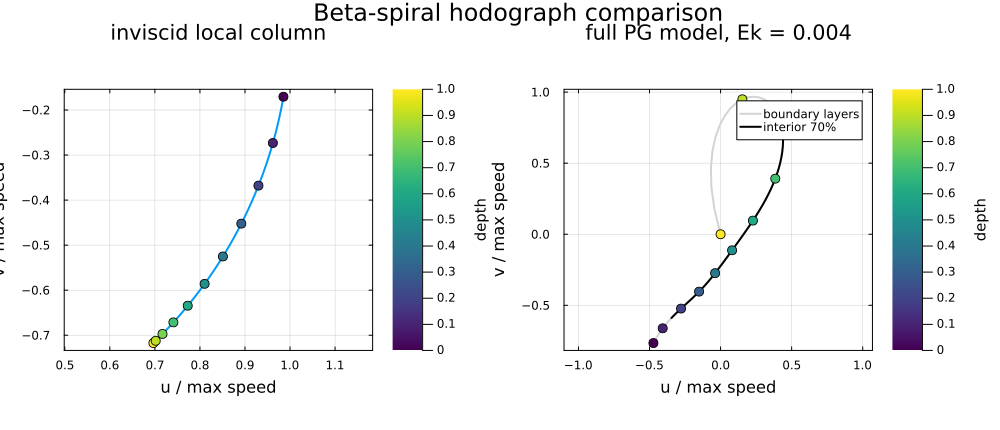

In [11]:
pg_column_x, pg_column_y = -0.4, -0.4
pg_z = collect(range(-pg_H, 0.0; length=Nz))
pg_velocity = [
    horizontal_velocity(pg_solution, pg_column_x, pg_column_y, zz)
    for zz in pg_z
]
pg_u = getproperty.(pg_velocity, :u)
pg_v = getproperty.(pg_velocity, :v)
pg_speed = hypot.(pg_u, pg_v)
pg_scale = maximum(pg_speed)
pg_interior = findall(zz -> -0.85pg_H <= zz <= -0.15pg_H, pg_z)

synthetic_scale = maximum(hypot.(u, v))
synthetic_hodograph = plot(
    u ./ synthetic_scale, v ./ synthetic_scale;
    xlabel="u / max speed", ylabel="v / max speed", aspect_ratio=:equal,
    title="inviscid local column", label=false,
)
scatter!(synthetic_hodograph, u[levels] ./ synthetic_scale, v[levels] ./ synthetic_scale;
    marker_z=depth[levels], color=:viridis, markersize=5,
    colorbar_title="depth", label=false)

pg_hodograph = plot(
    pg_u ./ pg_scale, pg_v ./ pg_scale;
    xlabel="u / max speed", ylabel="v / max speed", aspect_ratio=:equal,
    color=:lightgray, title="full PG model, Ek = $(pg_Ek)", label="boundary layers",
)
plot!(pg_hodograph, pg_u[pg_interior] ./ pg_scale, pg_v[pg_interior] ./ pg_scale;
    color=:black, label="interior 70%")
scatter!(pg_hodograph, pg_u[levels] ./ pg_scale, pg_v[levels] ./ pg_scale;
    marker_z=(-pg_z[levels]), color=:viridis, markersize=5,
    colorbar_title="depth", label=false)

pg_comparison_hodographs = plot(
    synthetic_hodograph, pg_hodograph;
    layout=(1, 2), size=(1000, 430),
    plot_title="Beta-spiral hodograph comparison",
)
savefig(pg_comparison_hodographs, joinpath(@__DIR__, "pg_beta_spiral_model_hodographs.png"))
display(pg_comparison_hodographs)

### Turning and speed

The angle is unwrapped before differencing and referenced to the shallow edge of the interior interval. The synthetic column turns at constant speed by construction. The full PG solution turns while its speed changes substantially, and it approaches zero at the no-slip bottom. The reported interior turning excludes both boundary layers.

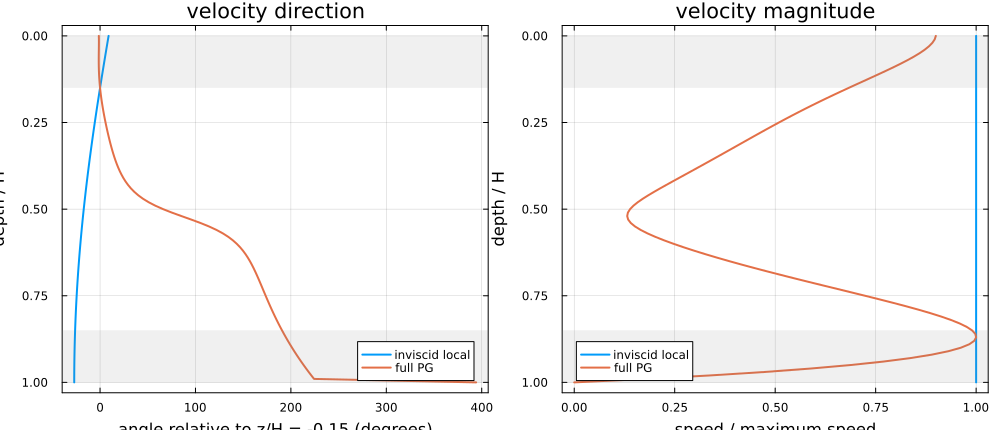

(Ekman_number = 0.004, comparison_location = (-0.4, -0.4), interior_depth_interval = (-0.85, -0.15), inviscid_turn_with_increasing_depth_degrees = -26.148348894099577, pg_turn_with_increasing_depth_degrees = 190.71779197576797, pg_interior_speed_range = (0.0002066361657603181, 0.0015519625594463387))

In [12]:
function unwrap_angles(angles)
    unwrapped = copy(angles)
    for k in 2:length(unwrapped)
        increment = mod(angles[k] - angles[k - 1] + pi, 2pi) - pi
        unwrapped[k] = unwrapped[k - 1] + increment
    end
    return unwrapped
end

synthetic_angles = unwrap_angles(atan.(v, u))
pg_angles = unwrap_angles(atan.(pg_v, pg_u))
synthetic_interior = findall(zz -> -0.85H <= zz <= -0.15H, z)

synthetic_angle_reference = synthetic_angles[last(synthetic_interior)]
pg_angle_reference = pg_angles[last(pg_interior)]
synthetic_turn_down = (
    synthetic_angles[first(synthetic_interior)] - synthetic_angle_reference
)
pg_turn_down = pg_angles[first(pg_interior)] - pg_angle_reference

angle_panel = plot(
    rad2deg.(synthetic_angles .- synthetic_angle_reference), depth;
    xlabel="angle relative to z/H = -0.15 (degrees)", ylabel="depth / H",
    yflip=true, label="inviscid local", title="velocity direction",
)
plot!(angle_panel, rad2deg.(pg_angles .- pg_angle_reference), -pg_z ./ pg_H;
    label="full PG")
hspan!(angle_panel, [0.0, 0.15]; color=:gray, alpha=0.12, label=false)
hspan!(angle_panel, [0.85, 1.0]; color=:gray, alpha=0.12, label=false)

speed_panel = plot(
    hypot.(u, v) ./ synthetic_scale, depth;
    xlabel="speed / maximum speed", ylabel="depth / H",
    yflip=true, label="inviscid local", title="velocity magnitude",
)
plot!(speed_panel, pg_speed ./ pg_scale, -pg_z ./ pg_H; label="full PG")
hspan!(speed_panel, [0.0, 0.15]; color=:gray, alpha=0.12, label=false)
hspan!(speed_panel, [0.85, 1.0]; color=:gray, alpha=0.12, label=false)

pg_profile_comparison = plot(angle_panel, speed_panel; layout=(1, 2), size=(1000, 430))
savefig(pg_profile_comparison, joinpath(@__DIR__, "pg_beta_spiral_model_profiles.png"))
display(pg_profile_comparison)

display((
    Ekman_number=pg_Ek,
    comparison_location=(pg_column_x, pg_column_y),
    interior_depth_interval=(-0.85, -0.15),
    inviscid_turn_with_increasing_depth_degrees=rad2deg(synthetic_turn_down),
    pg_turn_with_increasing_depth_degrees=rad2deg(pg_turn_down),
    pg_interior_speed_range=extrema(pg_speed[pg_interior]),
))

## Interpretation and limitations

- The spiral is a consequence of combining adiabatic density conservation with beta-plane vorticity conservation; beta supplies an absolute reference that thermal wind alone cannot provide.
- In this Northern Hemisphere subtropical example, equatorward flow generates downwelling and the absolute velocity turns clockwise with increasing depth. Upwelling or sufficiently strong local cooling reverses the sense of rotation.
- The inversion is local but needs stable horizontal density gradients over many depths. Schott and Stommel emphasized smoothing mesoscale eddy noise and avoiding strong currents where relative vorticity is not negligible.
- The small-$\mathrm{Ek}$ PG comparison retains vertical viscosity, buoyancy diffusion/restoring, surface forcing, bottom stress, and basin boundary conditions. Its selected equatorward-flowing interior column turns clockwise with depth like the inviscid spiral, but it need not obey equation (1.6) exactly.